In [12]:
import matplotlib.pyplot as plt
import numpy as np
import math
from scipy.linalg import expm

In [13]:


# GLOBAL STYLE SETTINGS (run once)

plt.rcParams.update({

    # --- FONT SIZES ---
    "font.size": 24,              # base font size
    "axes.titlesize": 20,         # title
    "axes.labelsize": 36,         # x/y labels
    "xtick.labelsize": 36,
    "ytick.labelsize": 36,
    "legend.fontsize": 16,

    # --- LINES ---
    "lines.linewidth": 5,
    "lines.markersize": 16,

    # --- FIGURE / AXIS ---
    "figure.figsize": (8, 6),
    "figure.dpi": 120,
    "axes.linewidth": 1.5,        # thicker axis spines

    # --- TICKS ---
    "xtick.major.size": 15,
    "xtick.major.width": 3,
    "ytick.major.size": 15,
    "ytick.major.width": 3,

    # --- LEGEND ---
    "legend.frameon": True,
    "legend.framealpha": 0.8,
    "legend.fancybox": True,

    # --- GRID (optional) ---
    #"axes.grid": True,
    #"grid.alpha": 0.3,
})


In [3]:
def compete_16x16_multinomial(
    tau,  nu, dt,
    PopSize=10**8,
    steps=1000
):
    """
    16x16 model:
      - TR and VR are two-locus genotypes with alleles 0..3 each -> 16 types (index = x*4 + y).
      - Fixed 9-state environment cycle (no zeros), in this order:
          [(1,1), (2,3), (3,2), (1,3), (2,1), (3,3), (1,2), (3,1), (2,2)]
      - Additive environment fitness for VR=(x,y) when environment=(E1,E2):
          H(x,y) = 0.5 * 1[x == E1] + 0.5 * 1[y == E2]
      - Reproduction: multinomial sampling with probabilities proportional to Pop * exp(H*dt)
      - TR mutation: each individual mutates with prob mu*dt to a uniformly random TR (16 types)
      - VR switching governed by TR = (a,b):
          * a!=0,b!=0 -> VR deterministically -> (a,b)
          * a==0,b!=0 -> VR.x uniform, VR.y = b
          * a!=0,b==0 -> VR.x = a, VR.y uniform
          * a==0,b==0 -> both loci uniform
      - Returns:
          freqTR: array of shape (T,16,16) of population fractions per step after transient cut
          AvH: array of shape (T,) average H per step after transient cut
    """

    # --- helper lists for decoding/encoding ---
    TR_pairs = [(i, j) for i in range(4) for j in range(4)]  # length 16
    VR_pairs = TR_pairs[:]  # same structure

    # --- initialize population evenly across 256 TRxVR cells ---
    Pop = np.zeros((16, 16), dtype=np.int64)
    base_each = PopSize // 256
    if base_each > 0:
        Pop[:] = base_each
    leftover = PopSize - Pop.sum()
    # give leftover to cell (0,0)
    if leftover > 0:
        Pop[0, 0] += leftover

    # --- fixed 9-state environment cycle as requested ---
    env_cycle_pairs = [
        (0,0),(1,1), (2,2), (3,3)
    ]
    # create Hcycle: each H is length-16 vector with additive contribution
    Hcycle = []
    for (E1, E2) in env_cycle_pairs:
        h = np.zeros(16, dtype=float)
        for idx, (x, y) in enumerate(VR_pairs):
            h[idx] =  (1 if x == E1 else 0) +  (1 if y == E2 else 0)
        Hcycle.append(h)

    n_env = len(Hcycle)
    Hindex = 0
    H = Hcycle[Hindex]
    next_switch = tau / dt

    freqTR = []
    AvH = []

    for k in range(steps):
        # ---- environment switch ----
        if k > next_switch:
            Hindex = (Hindex + 1) % n_env
            H = Hcycle[Hindex]
            next_switch += tau / dt

        # ---- SELECTION / REPRODUCTION ----
        # growth factors per VR type
        w = np.exp(H * dt)              # shape (16,)
        weighted = Pop * w[None, :]     # broadcast to (16,16)
        total_fit = weighted.sum()
        if total_fit <= 0:
            P_repro = np.ones((16,16), dtype=float) / 256.0
        else:
            P_repro = weighted / total_fit

        new_counts = np.random.multinomial(PopSize, P_repro.reshape(-1))
        Pop = new_counts.reshape(16, 16)

        # ---- VR SWITCHING per TR rules (four cases) ----
        if nu * dt > 0:
            for tr in range(16):
                a, b = TR_pairs[tr]
                for vr in range(16):
                    count = Pop[tr, vr]
                    if count == 0:
                        continue
                    s = np.random.binomial(count, nu * dt)
                    if s == 0:
                        continue
                    Pop[tr, vr] -= s

                    # Case 1: a != 0 and b != 0 -> deterministic VR -> (a,b)
                    if a != 0 and b != 0:
                        target = a * 4 + b
                        Pop[tr, target] += s

                    # Case 2: a == 0 and b != 0 -> VR.x uniform (0..3), VR.y = b
                    elif a == 0 and b != 0:
                        redist = np.random.multinomial(s, [1/4.0] * 4)
                        for x in range(4):
                            target = x * 4 + b
                            Pop[tr, target] += redist[x]

                    # Case 3: a != 0 and b == 0 -> VR.x = a, VR.y uniform
                    elif a != 0 and b == 0:
                        redist = np.random.multinomial(s, [1/4.0] * 4)
                        for y in range(4):
                            target = a * 4 + y
                            Pop[tr, target] += redist[y]

                    # Case 4: a == 0 and b == 0 -> both loci uniform
                    else:
                        Pop[tr, :] += np.random.multinomial(s, [1/16.0] * 16)

        # ---- statistics ----
        freqTR.append(Pop.astype(float) / PopSize)
        AvH.append(np.sum(Pop * H[None, :]) / PopSize)

    # discard initial transAient of 3 environment periods
    cut = 3 * int(tau / dt)
    freqTR = np.array(freqTR)
    AvH = np.array(AvH)


    return  np.mean(AvH[cut:])


In [4]:
import numpy as np
from joblib import Parallel, delayed


# --- Accelerate for a list of nu values using parallelization ---
def growth_for_nu_list( 
    tau, nu_list, dt,
    PopSize=10**8,
    steps=1000,
    n_jobs=-1):
    results = Parallel(n_jobs=n_jobs)(
        delayed(compete_16x16_multinomial)(tau, nu, dt,
    PopSize,
    steps) for nu in nu_list
    )
    return results

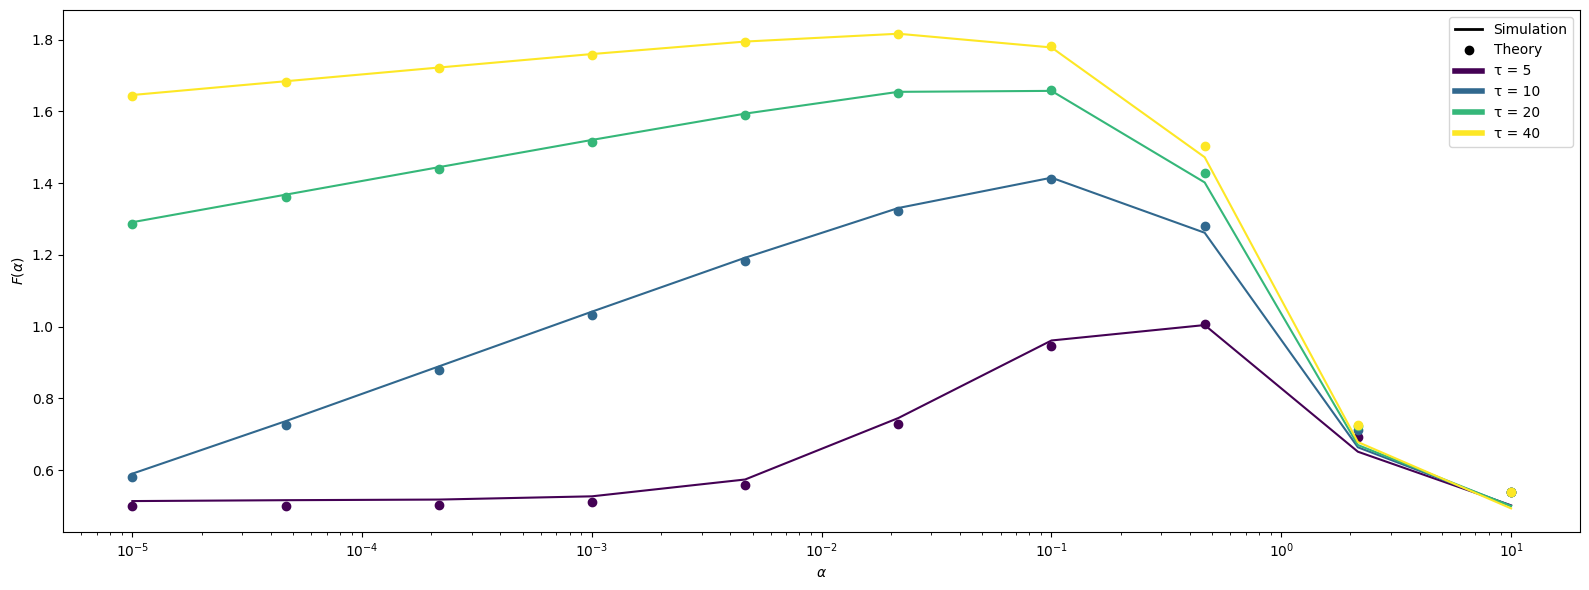

In [18]:
import numpy as np
from scipy.linalg import expm, eigvals

def A2_matrix(Hvec, mu, Q):
    """
    Générateur continu sur Q^2 états (i,j)
    """
    N = Q * Q

    # Fitness H(i,j) = H_i + H_j
    H2 = np.add.outer(Hvec, Hvec).reshape(N)

    A = np.full((N, N), mu / N)
    np.fill_diagonal(A, H2 - mu * (N - 1) / N)

    return A

def Mcycle2(Hvec, mu, Q, tau):
    """
    Matrice de Floquet sur un cycle complet (Q étapes)
    """
    N = Q * Q
    M = np.eye(N)

    for k in range(Q):
        Hk = np.roll(Hvec, k)
        M = expm(A2_matrix(Hk, mu, Q) * tau) @ M

    return M

def rInf2(Hvec, mu, Q, tau):
    M = Mcycle2(Hvec, mu, Q, tau)
    rho = np.max(np.abs(eigvals(M)))
    return np.log(rho) / (Q * tau)



# === Parameters ===
Q = 4
Hvec = np.array([1.0] + [0.0]*(Q-1))
taus = [5, 10, 20, 40]
dt=1e-1
PopSize=10**15
mu_list = np.logspace(-5, 1, 100)  # equivalent to ν in your Mathematica code
nu_list=np.logspace(-5,1,10)
# === Compute theory curves ===
theory_data = {}
for tau in taus:
    theory_data[tau] = [rInf2(Hvec, mu, Q, tau) for mu in mu_list]

# === Optional: save to CSV to compare with simulation ===
df_list = []
for tau in taus:
    for mu, r in zip(mu_list, theory_data[tau]):
        df_list.append([tau, mu, r])
df_theory = pd.DataFrame(df_list, columns=["tau", "nu", "rInf"])
df_theory.to_csv("growth_data.csv", index=False)

# === Load simulation results (replace with your own growth_for_nu_list function) ===
# from your previous Monte Carlo simulations
# results_sim = growth_for_nu_list(Q, tau, mu_list, dt, PopSize)

# --- Plot ---
plt.figure(figsize=(16,6))
colors = plt.cm.viridis(np.linspace(0, 1, len(taus)))

for color, tau in zip(colors, taus):
    results = growth_for_nu_list(tau, nu_list, dt,
    PopSize,
    steps=20000)  # your stochastic sim
    plt.semilogx(nu_list, results, '-', color=color)

    # --- Theory (points) ---
    # Subsample points for clarity
    idx = np.linspace(0, len(mu_list)-1, min(10, len(mu_list)), dtype=int)
    plt.scatter(np.array(mu_list)[idx], np.array(theory_data[tau])[idx],
                color=color, marker='o')

# --- Custom legend ---
legend_lines = [Line2D([0], [0], color='k', lw=2, label='Simulation'),
                Line2D([0], [0], marker='o', color='w', markerfacecolor='k',
                       markeredgecolor='k', label='Theory')]

tau_handles = [Line2D([0], [0], color=color, lw=4, label=f'τ = {tau}') 
               for color, tau in zip(colors, taus)]

plt.legend(handles=legend_lines + tau_handles)
plt.xlabel(r"$\alpha$")
plt.ylabel(r"$F(\alpha)$")
plt.xscale("log")
plt.tight_layout()
#plt.savefig('Effective_Growth_VR.svg')
plt.show()



In [4]:
import numpy as np
from scipy.linalg import expm, eigvals

In [5]:
import numpy as np
import itertools

def compete_64x64_multinomial(
    tau, nu, dt,
    PopSize=10**8,
    steps=1000
):
    """
    64x64 model (3 loci, 4 alleles each)

    - TR and VR: (x,y,z), x,y,z in {0,1,2,3} → 64 types
    - Environment: fixed 3-state cycle of (E1,E2,E3)
    - Fitness:
        H = (1/3) * sum_l 1[VR_locus == E_locus]
    - Reproduction: multinomial ∝ Pop * exp(H*dt)
    - VR switching:
        For each locus:
          TR_locus != 0 → VR_locus = TR_locus
          TR_locus == 0 → VR_locus uniform
    """

    # --- genotype lists ---
    TR_triplets = list(itertools.product(range(4), repeat=3))
    VR_triplets = TR_triplets[:]          # same structure
    n = 64

    # --- initialize population uniformly ---
    Pop = np.zeros((n, n), dtype=np.int64)
    base = PopSize // (n * n)
    Pop[:] = base
    Pop[0, 0] += PopSize - Pop.sum()

    # --- 3-state environment cycle ---
    env_cycle = [
        (0, 0, 0),
        (1, 1, 1),
        (2, 2, 2),
        (3, 3, 3),
    ]

    Hcycle = []
    for E in env_cycle:
        h = np.zeros(n)
        for i, (x, y, z) in enumerate(VR_triplets):
            h[i] = (
                (x == E[0]) +
                (y == E[1]) +
                (z == E[2])
            ) 
        Hcycle.append(h)

    n_env = len(Hcycle)
    Hindex = 0
    H = Hcycle[Hindex]
    next_switch = tau / dt

    AvH = []

    for k in range(steps):

        # --- environment switching ---
        if k > next_switch:
            Hindex = (Hindex + 1) % n_env
            H = Hcycle[Hindex]
            next_switch += tau / dt

        # --- selection / reproduction ---
        w = np.exp(H * dt)
        weighted = Pop * w[None, :]
        total = weighted.sum()

        if total <= 0:
            P = np.ones((n, n)) / (n * n)
        else:
            P = weighted / total

        Pop = np.random.multinomial(
            PopSize, P.reshape(-1)
        ).reshape(n, n)

        # --- VR switching ---
        if nu * dt > 0:
            for tr in range(n):
                a, b, c = TR_triplets[tr]

                for vr in range(n):
                    count = Pop[tr, vr]
                    if count == 0:
                        continue

                    s = np.random.binomial(count, nu * dt)
                    if s == 0:
                        continue

                    Pop[tr, vr] -= s

                    # per-locus target sets
                    xs = [a] if a != 0 else range(4)
                    ys = [b] if b != 0 else range(4)
                    zs = [c] if c != 0 else range(4)

                    targets = [
                        (x, y, z)
                        for x in xs for y in ys for z in zs
                    ]

                    probs = [1 / len(targets)] * len(targets)
                    redist = np.random.multinomial(s, probs)

                    for cnt, (x, y, z) in zip(redist, targets):
                        idx = x * 16 + y * 4 + z
                        Pop[tr, idx] += cnt

        # --- statistics ---
        AvH.append(np.sum(Pop * H[None, :]) / PopSize)

    cut = 3 * int(tau / dt)
    AvH = np.array(AvH)

    return np.mean(AvH[cut:])


In [6]:
import numpy as np
from joblib import Parallel, delayed
import pandas as pd


# --- Accelerate for a list of nu values using parallelization ---
def growth_for_nu_list( 
    tau, nu_list, dt,
    PopSize=10**8,
    steps=1000,
    n_jobs=-1):
    results = Parallel(n_jobs=n_jobs)(
        delayed(compete_64x64_multinomial)(tau, nu, dt,
    PopSize,
    steps) for nu in nu_list
    )
    return results

In [7]:
import numpy as np
from scipy.linalg import expm, eigvals
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

def A3_matrix(Hvec, mu, Q):
    """
    Continuous-time generator on Q^3 states (i,j,k)
    """
    N = Q**3

    # Fitness H(i,j,k) = H_i + H_j + H_k
    H3 = (
        Hvec[:, None, None]
        + Hvec[None, :, None]
        + Hvec[None, None, :]
    ).reshape(N)

    # Uniform mutation to any state
    A = np.full((N, N), mu / N)
    np.fill_diagonal(A, H3 - mu * (N - 1) / N)

    return A

def Mcycle3(Hvec, mu, Q, tau, env_cycle=[0, 1, 2,3] ):
    """
    Floquet matrix over one full environment cycle
    env_cycle = list of shifts applied to Hvec
    """
    N = Q**3
    M = np.eye(N)

    for shift in env_cycle:
        Hk = np.roll(Hvec, shift)
        M = expm(A3_matrix(Hk, mu, Q) * tau) @ M

    return M

def rInf3(Hvec, mu, Q, tau, env_cycle=[0,1,2,3]):
    M = Mcycle3(Hvec, mu, Q, tau, env_cycle)
    rho = np.max(np.abs(eigvals(M)))
    return np.log(rho) / (len(env_cycle) * tau)




# === Parameters ===
Q = 4
Hvec = np.array([1.0] + [0.0]*(Q-1))
taus = [5, 10, 20, 40]
dt=1e-1
PopSize=10**15
mu_list = np.logspace(-5, 1, 100)  # equivalent to ν in your Mathematica code
nu_list=np.logspace(-5,1,10)
# === Compute theory curves ===
theory_data = {}
for tau in taus:
    theory_data[tau] = [rInf3(Hvec, mu, Q, tau) for mu in mu_list]

# === Optional: save to CSV to compare with simulation ===
df_list = []
for tau in taus:
    for mu, r in zip(mu_list, theory_data[tau]):
        df_list.append([tau, mu, r])
df_theory = pd.DataFrame(df_list, columns=["tau", "nu", "rInf"])
df_theory.to_csv("growth_data.csv", index=False)

# === Load simulation results (replace with your own growth_for_nu_list function) ===
# from your previous Monte Carlo simulations
# results_sim = growth_for_nu_list(Q, tau, mu_list, dt, PopSize)

# --- Plot ---
plt.figure(figsize=(16,6))
colors = plt.cm.viridis(np.linspace(0, 1, len(taus)))

for color, tau in zip(colors, taus):
    print(tau)
    results = growth_for_nu_list(tau, nu_list, dt,
    PopSize,
    steps=10000)  # your stochastic sim
    plt.semilogx(nu_list, results, '-', color=color)

    # --- Theory (points) ---
    # Subsample points for clarity
    idx = np.linspace(0, len(mu_list)-1, min(10, len(mu_list)), dtype=int)
    plt.scatter(np.array(mu_list)[idx], np.array(theory_data[tau])[idx],
                color=color, marker='o')

# --- Custom legend ---
legend_lines = [Line2D([0], [0], color='k', lw=2, label='Simulation'),
                Line2D([0], [0], marker='o', color='w', markerfacecolor='k',
                       markeredgecolor='k', label='Theory')]

tau_handles = [Line2D([0], [0], color=color, lw=4, label=f'τ = {tau}') 
               for color, tau in zip(colors, taus)]

plt.legend(handles=legend_lines + tau_handles)
plt.xlabel(r"$\alpha$")
plt.ylabel(r"$F(\alpha)$")
plt.xscale("log")
plt.tight_layout()
#plt.savefig('Effective_Growth_VR.svg')
plt.show()



5


KeyboardInterrupt: 

<Figure size 1920x720 with 0 Axes>

# Testing first order perturbation theory

In [8]:


def eigenvalues_A0_first_order(L, nu):
    m = np.array([math.comb(L, k) for k in range(L + 1)], dtype=float)
    k = np.arange(L + 1, dtype=float)

    # λ_k = k - ν + (ν / 2^L) * C(L,k)
    lambdas = k - nu + (nu / 2**L) * m
    return lambdas

def eigenvectors_A0_first_order(L, nu):
    dim = L + 1

    m = np.array([math.comb(L, k) for k in range(dim)], dtype=float)
    v = np.sqrt(m)

    # matrice des vecteurs propres
    eigvecs = np.eye(dim)

    pref = nu / 2**L

    for k in range(dim):
        for j in range(dim):
            if j != k:
                eigvecs[j, k] += pref * v[k] * v[j] / (k - j)

    return eigvecs

def A0_approx(L,nu):
    lambdas = eigenvalues_A0_first_order(L, nu)
    eigvecs = eigenvectors_A0_first_order(L, nu)
    return eigvecs @ np.diag(lambdas) @ eigvecs.T


def eigenvalues_A1_first_order(L, nu):
    m = np.array([math.comb(L, k) for k in range(L + 1)], dtype=float)
    k = np.arange(L + 1, dtype=float)

    # λ_k = L-k - ν + (ν / 2^L) * C(L,k)
    lambdas = L-k - nu + (nu / 2**L) * m
    return lambdas

def eigenvectors_A1_first_order(L, nu):
    dim = L + 1

    m = np.array([math.comb(L, k) for k in range(dim)], dtype=float)
    v = np.sqrt(m)

    # matrice des vecteurs propres
    eigvecs = np.eye(dim)

    pref = nu / 2**L

    for k in range(dim):
        for j in range(dim):
            if j != k:
                eigvecs[j, k] += pref * v[k] * v[j] / (j - k)

    return eigvecs

def A1_approx(L,nu):
    lambdas = eigenvalues_A1_first_order(L, nu)
    eigvecs = eigenvectors_A1_first_order(L, nu)
    return eigvecs @ np.diag(lambdas) @ eigvecs.T

In [9]:
def r_inf_exact_Q2(L, tau, nu):
    m = np.array([math.comb(L, k) for k in range(L+1)])
    A0 = (nu / 2**L) * np.outer(np.sqrt(m), np.sqrt(m))
    A1 = A0.copy()

    # Correct diagonal
    A0 += np.diag(np.arange(L+1) - nu )
    A1 += np.diag(L - np.arange(L+1) - nu )

    M = expm(A1 * tau) @ expm(A0 * tau)
    lam_max = np.max(np.real(np.linalg.eigvals(M)))
    return np.log(lam_max) / (2 * tau)

def r_inf_approx_Q2(L, tau, nu):
    lambdas_0 = np.exp(tau*eigenvalues_A0_first_order(L, nu))
    eigvecs_0 = eigenvectors_A0_first_order(L, nu)
    lambdas_1 = np.exp(tau*eigenvalues_A1_first_order(L, nu))
    eigvecs_1 = eigenvectors_A1_first_order(L, nu)
    #print(eigvecs_1)
    #print(eigvecs_0)
    #print(eigvecs_1.T @ eigvecs_0 )
    approx=np.eye(L+1)
    for k in range(L+1):
        for l in range(L+1):
            if k!=l:
                approx[k,l]=2*nu/2**L*np.sqrt(math.comb(L,k)*math.comb(L,l))/(l-k)

    M=eigvecs_1 @ np.diag(lambdas_1) @ approx @ np.diag(lambdas_0) @ eigvecs_0.T

    C=eigvecs_0.T @ eigvecs_1
    S=lambdas_1[0]*lambdas_0[-1]*C[-1,0]**2
    lam_max =max(S,np.exp(L*tau))# max(M[L,L],np.exp(L*tau))#S
    return np.log(lam_max) / (2 * tau)

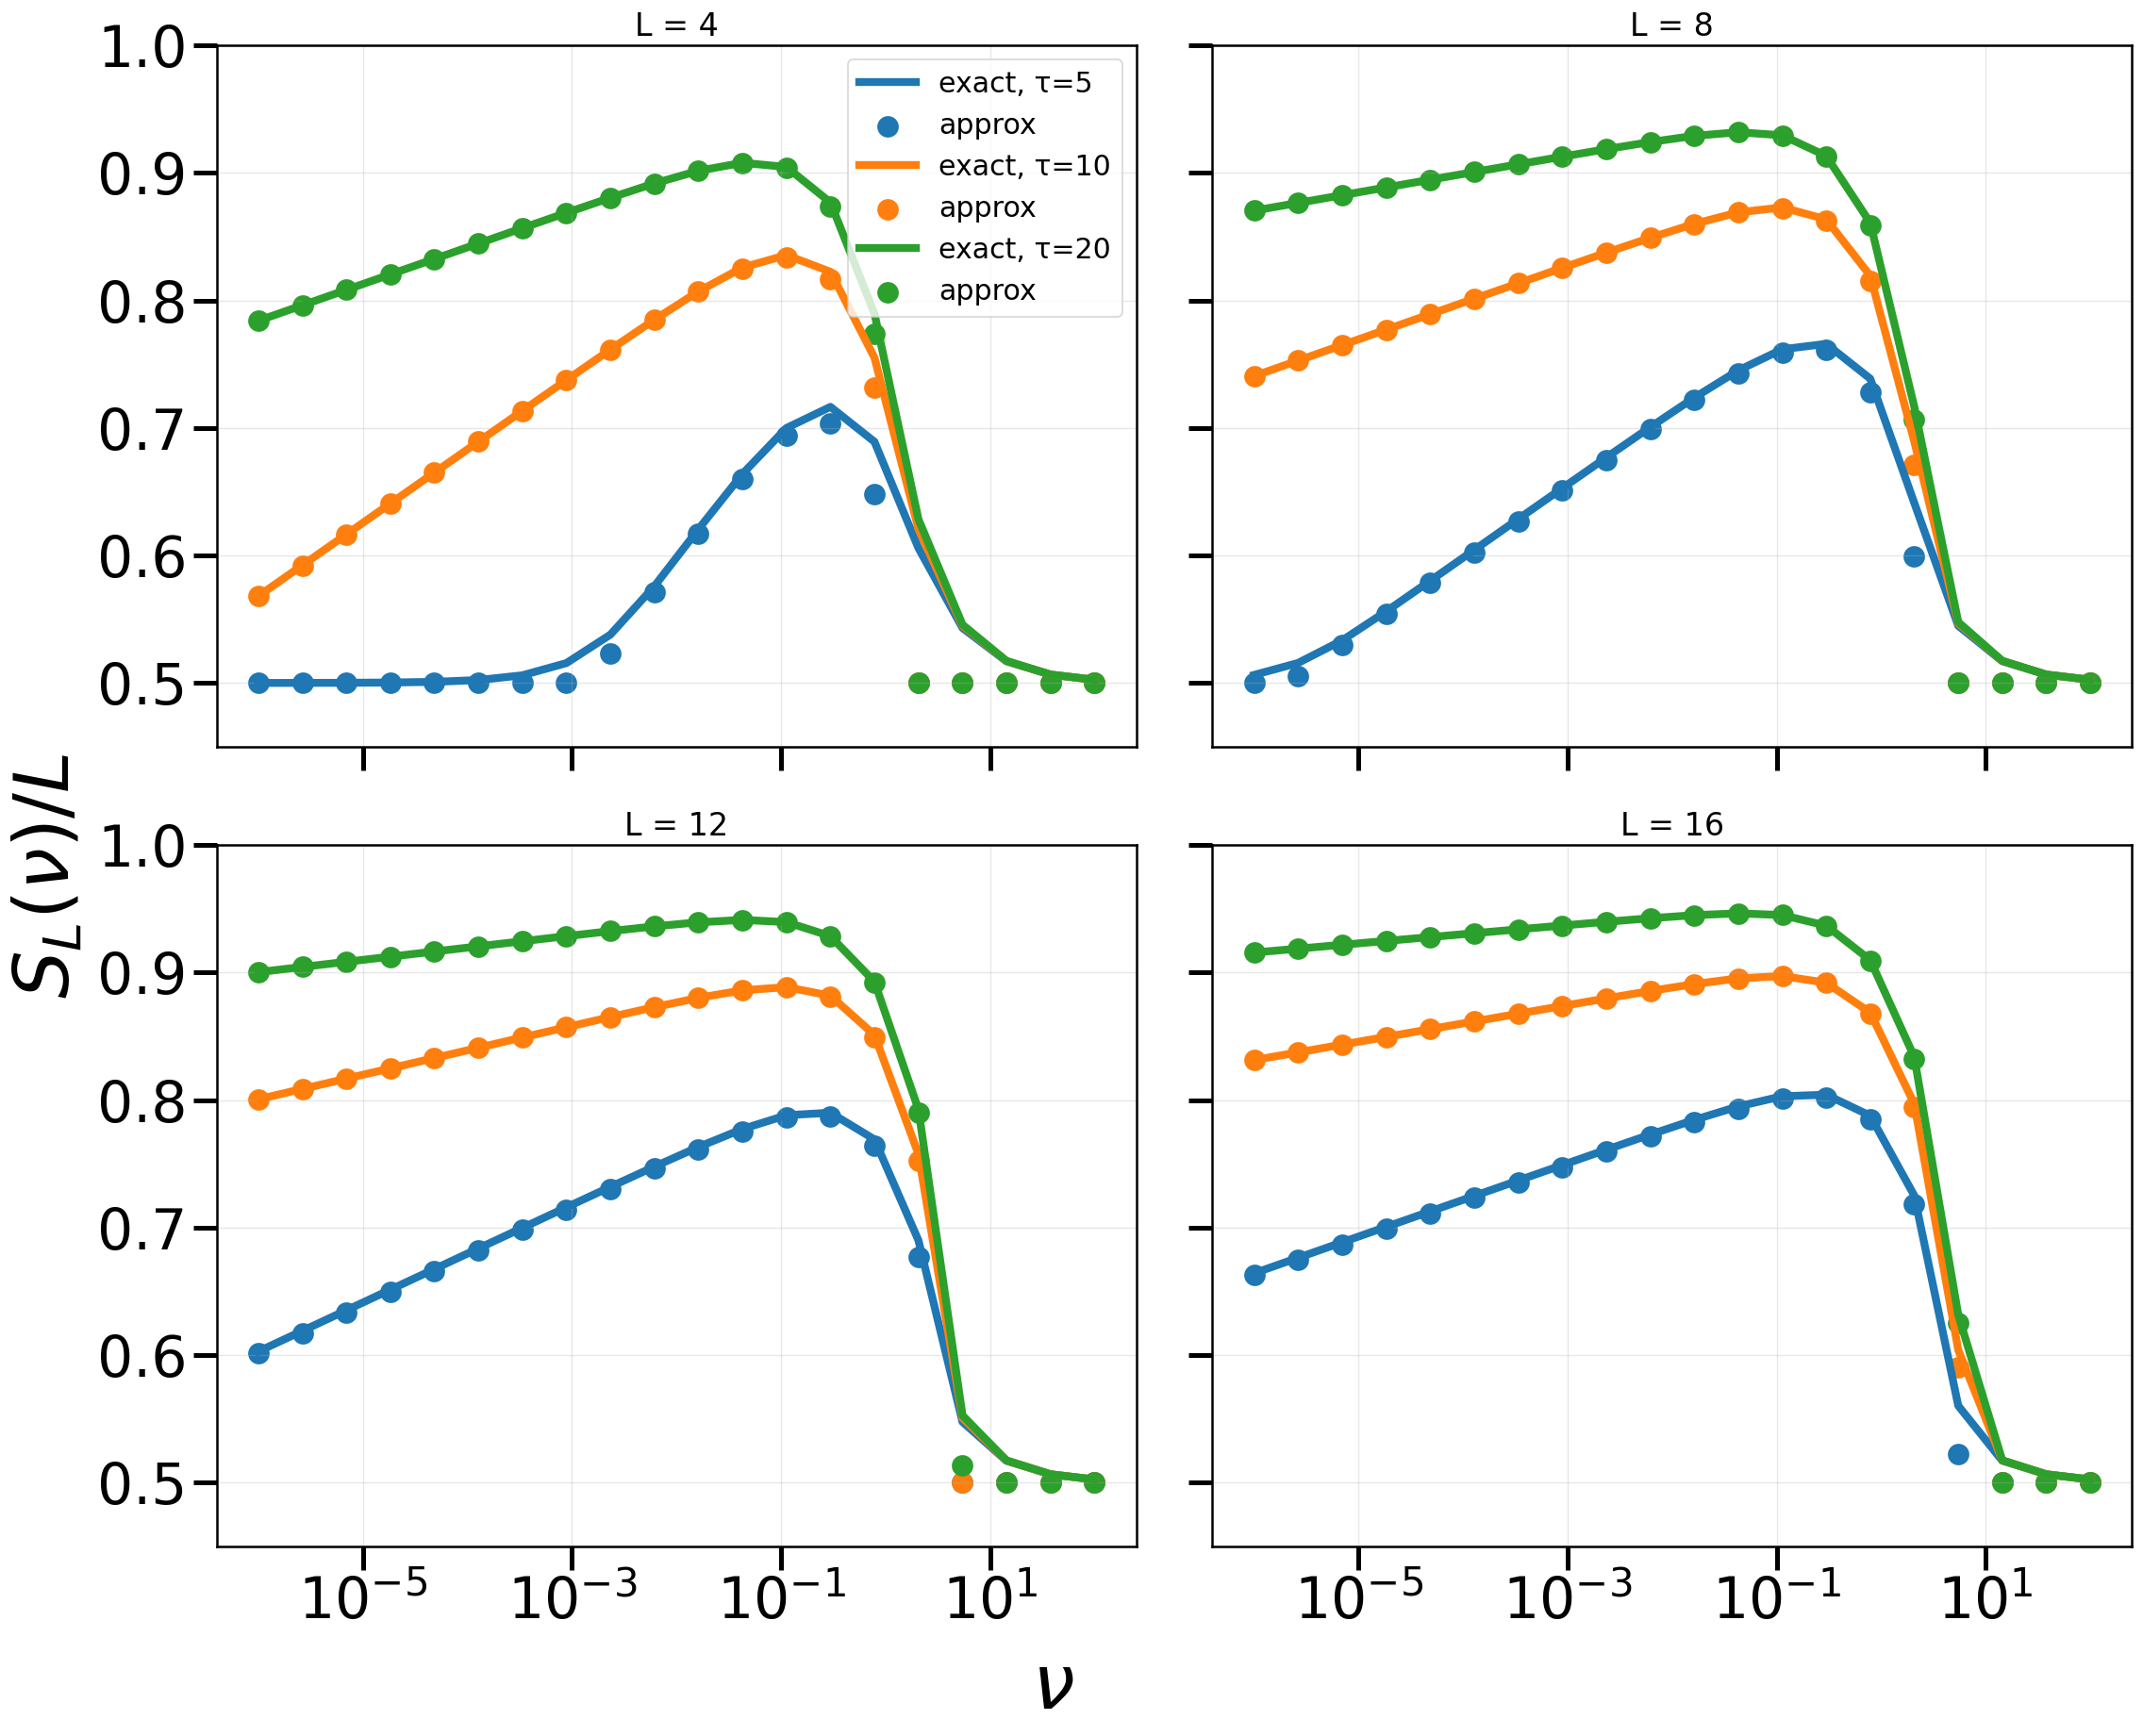

In [10]:
import matplotlib.pyplot as plt
import numpy as np

Ls = [4,8,12,16]
taus = [5, 10, 20]
nu_list = np.logspace(-6, 2, 20)

fig, axes = plt.subplots(2, 2, figsize=(20, 16), sharex=True, sharey=True)
axes = axes.flatten()

for ax, L in zip(axes, Ls):
    for tau in taus:
        exact = [r_inf_exact_Q2(L, tau, nu)/L for nu in nu_list]
        approx = [r_inf_approx_Q2(L, tau, nu)/L for nu in nu_list]

        ax.plot(nu_list, exact, label=f"exact, τ={tau}")
        ax.scatter(nu_list, approx, s=160, label=f"approx")

    ax.set_title(f"L = {L}")
    ax.set_xscale("log")
    ax.set_ylim(0.45, 1)
    ax.grid(True, alpha=0.3)

# Legend only in the first panel
axes[0].legend(fontsize=18)

# Common labels
fig.text(0.5, 0.04, r"$\nu$", ha="center",fontsize=48)
fig.text(0.04, 0.5, r"$S_L(\nu) / L$", va="center", rotation="vertical",fontsize=48)

plt.tight_layout(rect=[0.06, 0.06, 1, 1])
plt.savefig('S_L.svg')
plt.savefig('S_L.png')
plt.show()


# Check subspace 

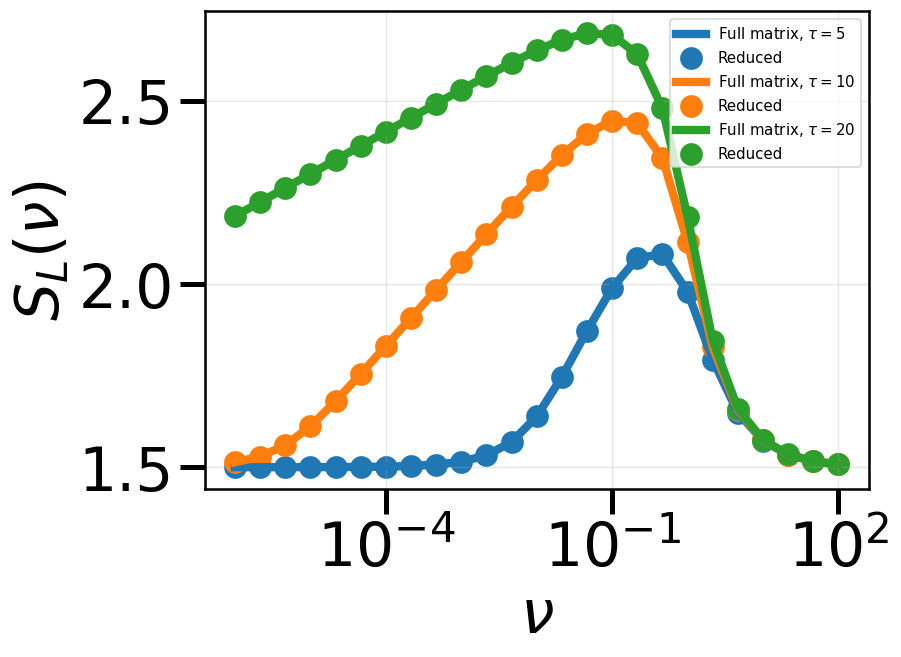

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
import math

Q = 2
L = 3
taus = [5, 10, 20]
nu_list = np.logspace(-6, 2, 25)

# --- Exact A3 generator ---
def A3_matrix(Hvec, mu, Q):
    N = Q**3
    H3 = (Hvec[:, None, None]
        + Hvec[None, :, None]
        + Hvec[None, None, :]).reshape(N)

    A = np.full((N, N), mu / N)
    np.fill_diagonal(A, H3 - mu * (N-1)/N)
    return A

# --- Reduced exact Q=2 ---
def r_inf_exact_Q2(L, tau, nu):
    m = np.array([math.comb(L, k) for k in range(L+1)])
    A0 = (nu / 2**L) * np.outer(np.sqrt(m), np.sqrt(m))
    A1 = A0.copy()

    A0 += np.diag(np.arange(L+1) - nu)
    A1 += np.diag(L - np.arange(L+1) - nu)

    M = expm(A1 * tau) @ expm(A0 * tau)
    lam_max = np.max(np.real(np.linalg.eigvals(M)))
    return np.log(lam_max) / (2 * tau)

# --- Build A3 matrices (fixed structure, varying nu) ---
Hvec1 = np.array([1.0, 0.0])
Hvec2 = np.array([0.0, 1.0])

# --- Plot ---


for tau in taus:
    r_A3 = []
    r_Q2 = []

    for nu in nu_list:
        A3 = A3_matrix(Hvec1, nu, Q)
        A3_bis = A3_matrix(Hvec2, nu, Q)

        M = expm(A3 * tau) @ expm(A3_bis * tau)
        lam_max = np.max(np.real(np.linalg.eigvals(M)))
        r_A3.append(np.log(lam_max) / (2 * tau))

        r_Q2.append(r_inf_exact_Q2(L, tau, nu))

    plt.plot(nu_list, r_A3, label=rf"Full matrix, $\tau={tau}$")
    plt.scatter(nu_list, r_Q2, s=160, label=rf"Reduced")

plt.xscale("log")
plt.xlabel(r"$\nu$")
plt.ylabel(r"$S_L(\nu)$")
plt.legend(fontsize=9)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('Reduction.svg')
plt.savefig('Reduction.png')
plt.show()
